In [2]:
from p1.dataset import load_csv_data
from p1.config import RAW_DATA_DIR
import numpy as np
import pickle

2026-10-25 17:58:36.379 | INFO     | p1.config:<module>:11 - PROJ_ROOT path is: /home/mpj/repositories/epfl_ml_p1


In [ ]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(RAW_DATA_DIR)

In [ ]:

y_train[y_train==-1]=0

In [9]:
# import pickle
import pickle

# save the data to a pickle file
# joblib.dump(x_train, "x_train.pkl")
pickle.dump(x_train, open(RAW_DATA_DIR/"x_train.pkl", "wb"))
pickle.dump(x_test, open(RAW_DATA_DIR/"x_test.pkl", "wb"))
pickle.dump(y_train, open(RAW_DATA_DIR/"y_train.pkl", "wb"))
pickle.dump(train_ids, open(RAW_DATA_DIR/"train_ids.pkl", "wb"))
pickle.dump(test_ids, open(RAW_DATA_DIR/"test_ids.pkl", "wb"))


In [ ]:
# convert the labels for y
# pickle.dump(y_train, open(RAW_DATA_DIR/"y_train.pkl", "wb"))

In [3]:
# load the data from the pickle file
x_train: np.ndarray = pickle.load(open(RAW_DATA_DIR/"x_train.pkl", "rb"))
x_test: np.ndarray = pickle.load(open(RAW_DATA_DIR/"x_test.pkl", "rb"))
y_train: np.ndarray = pickle.load(open(RAW_DATA_DIR/"y_train.pkl", "rb"))
train_ids: np.ndarray = pickle.load(open(RAW_DATA_DIR/"train_ids.pkl", "rb"))
test_ids: np.ndarray = pickle.load(open(RAW_DATA_DIR/"test_ids.pkl", "rb"))

# Return later and make it more reproducible!

In [3]:
### see for how many columns we have nan
missing_data = \
(np.isnan(x_train).sum(axis=0)/x_train.shape[0]).round(3)

In [4]:
import matplotlib.pyplot as plt



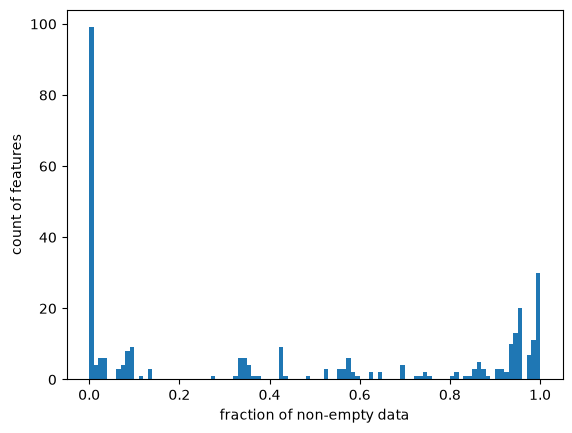

In [5]:
plt.figure()
plt.hist(missing_data, bins=100)
plt.xlabel('fraction of non-empty data')
plt.ylabel('count of features')
plt.show()

In [6]:
missing_data

array([0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.425, 0.425, 1.   , 0.425, 0.425, 1.   , 0.425, 0.425, 0.425,
       0.575, 0.575, 0.575, 0.575, 0.998, 0.575, 0.577, 0.587, 0.   ,
       0.   , 0.   , 0.487, 0.   , 0.   , 0.   , 0.   , 0.   , 0.598,
       0.   , 0.133, 0.133, 0.   , 0.   , 0.866, 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.871, 0.   , 0.   , 0.   , 0.   ,
       0.425, 0.97 , 0.425, 0.   , 0.   , 0.   , 0.008, 0.01 , 0.012,
       0.013, 0.852, 0.021, 0.024, 0.025, 0.027, 0.028, 0.029, 0.03 ,
       0.032, 0.583, 0.861, 0.723, 0.034, 0.036, 0.521, 0.522, 0.523,
       0.063, 0.066, 0.068, 0.071, 0.072, 0.075, 0.08 , 0.329, 0.333,
       0.333, 0.334, 0.552, 0.553, 0.087, 0.692, 0.692, 0.692, 0.698,
       0.091, 0.093, 0.569, 0.567, 0.095, 0.098, 0.742, 0.742, 0.813,
       0.813, 0.934, 0.934, 0.934, 0.934, 0.934, 0.934, 0.934, 0.934,
       0.934, 0.754, 0.946, 0.946, 0.946, 0.946, 0.946, 0.946, 0.946,
       0.809, 0.993,

In [7]:
# count of features with 100% and 0% of entries.
print((missing_data<=0.01).sum())
### select those variables
selected_vars = missing_data<=0.01
trim_x_train = x_train[:, selected_vars]

100


In [8]:
v = x_train[:, 10]
v[~np.isnan(v)].mean()

v

array([nan,  1.,  1., ...,  1.,  1.,  1.], shape=(328135,))

In [9]:
trim_x_train.shape

np.isnan(trim_x_train).sum()

def nan_to_mean(a: np.ndarray):
    # assert a.shape[0] == selected_data.shape[0]
    m = np.mean(a[~np.isnan(a)])
    return np.nan_to_num(a, m)

mean_trim_x_train = np.apply_along_axis(lambda a: nan_to_mean(a), axis=0, arr=trim_x_train)

### Check for matrix correlations!

In [10]:

corrs = np.corrcoef(mean_trim_x_train, rowvar=False)
feats_to_drop = np.zeros(corrs.shape[0], dtype=np.bool)
for i in range(corrs.shape[0]):
    for j in range(i+1, corrs.shape[1]):
        if abs(corrs[i,j]) > 0.7:
            print(f"correlation between {i} and {j} is {corrs[i,j]}")
            feats_to_drop[i] = True
feats_to_drop=np.array(feats_to_drop)

decorr_mean_trim_x_train = mean_trim_x_train[:, ~feats_to_drop]

correlation between 0 and 38 is 0.9999953430527992
correlation between 1 and 2 is 0.8690299774709292
correlation between 1 and 3 is 0.8691511626034337
correlation between 2 and 3 is 0.9997155094439815
correlation between 6 and 86 is 0.7112867497466885
correlation between 6 and 92 is 0.7058176322567661
correlation between 6 and 98 is 0.7641556832138682
correlation between 6 and 99 is 0.7600560882289781
correlation between 7 and 8 is 1.0
correlation between 17 and 47 is 0.7955423528442555
correlation between 19 and 50 is 0.7559319609393945
correlation between 29 and 64 is 0.9804142519728682
correlation between 34 and 65 is 0.8358806125632904
correlation between 39 and 41 is 0.9537183679568506
correlation between 41 and 43 is 0.725729125880181
correlation between 45 and 58 is 0.7600403020198956
correlation between 45 and 59 is 0.9689382507753427
correlation between 45 and 60 is 0.7367638430970768
correlation between 45 and 61 is 0.7098119165595033
correlation between 48 and 49 is 0.734635

In [11]:
mean_trim_x_train.shape

(328135, 100)

In [12]:
decorr_mean_trim_x_train.shape

(328135, 54)

In [13]:
### apply the same on the test; save the dat

trim_x_test = x_test[:, selected_vars]
mean_trim_x_test = np.apply_along_axis(lambda a: nan_to_mean(a), axis=0, arr=trim_x_test)
decorr_mean_trim_x_test = mean_trim_x_test[:, ~feats_to_drop]

In [14]:
from p1.config import INTERIM_DATA_DIR
pickle.dump(decorr_mean_trim_x_train, open(INTERIM_DATA_DIR / 'decorr_mean_trim_x_train.pkl', 'wb'))
pickle.dump(decorr_mean_trim_x_test, open(INTERIM_DATA_DIR / 'decorr_mean_trim_x_test.pkl', 'wb'))

In [5]:
from p1.config import INTERIM_DATA_DIR
decorr_mean_trim_x_train = pickle.load(open(INTERIM_DATA_DIR / 'decorr_mean_trim_x_train.pkl', 'rb'))
decorr_mean_trim_x_test = pickle.load(open(INTERIM_DATA_DIR / 'decorr_mean_trim_x_test.pkl', 'rb'))

### Fit and evaluate!

In [6]:
from p1.modeling.train import mean_squared_error_gd, mean_squared_error_sgd, least_squares, ridge_regression, logistic_regression, reg_logistic_regression, reg_logistic_regression

### msegd

In [7]:
# for now just fit



# yeah, had to standarize
std_decorr_mean_trim_x_train = (decorr_mean_trim_x_train - np.mean(decorr_mean_trim_x_train, axis=0)[np.newaxis, :]) / np.std(decorr_mean_trim_x_train, axis=0)[np.newaxis, :]
bias_std_decorr_mean_trim_x_train = np.hstack((np.ones((std_decorr_mean_trim_x_train.shape[0], 1)), std_decorr_mean_trim_x_train))


0.1429809445869339


In [22]:

bias_decorr_mean_trim_x_train = np.hstack((np.ones((decorr_mean_trim_x_train.shape[0], 1)), decorr_mean_trim_x_train))
msegd_w, msegd_loss = mean_squared_error_gd(y_train, bias_std_decorr_mean_trim_x_train, initial_w=np.zeros(bias_std_decorr_mean_trim_x_train.shape[1]), max_iters=25, gamma=0.1)
print(msegd_loss)


0.03513039742404883


In [23]:

# np.random.seed(42)
msesgd_w, msesgd_loss = mean_squared_error_sgd(y_train, bias_std_decorr_mean_trim_x_train, initial_w=np.zeros(bias_std_decorr_mean_trim_x_train.shape[1]), max_iters=25*1000, gamma=0.0001)
print(msesgd_loss)


0.03526245167609828


In [18]:
decorr_mean_trim_x_train.shape

(328135, 54)

In [24]:
ls_w, ls_loss = least_squares(y_train, bias_std_decorr_mean_trim_x_train)
ls_loss

0.035089717028700944

In [21]:
rr_w, rr_loss = ridge_regression(y_train, bias_std_decorr_mean_trim_x_train, 0.0001)
rr_loss

0.035089717260102904

### logistc regression

In [19]:
lr_w, lr_loss = logistic_regression(y_train, bias_std_decorr_mean_trim_x_train, initial_w=np.zeros(bias_std_decorr_mean_trim_x_train.shape[1]), max_iters=25, gamma=0.1)
lr_loss

0.42392420918392487

### Penalized logistic regression

In [20]:
plr_w, plr_loss = reg_logistic_regression(y_train, bias_std_decorr_mean_trim_x_train, 0.0001, initial_w=np.zeros(bias_std_decorr_mean_trim_x_train.shape[1]), max_iters=25, gamma=0.1)
plr_loss

0.423965882180029

In [ ]:
### check 

### Train proper guys

In [53]:
from p1.modeling.models import RidgeRegress, RegLogisticRegress, LinearRegressLS, LinearRegressGD, LinearRegressSGD, RidgeRegress, RegLogisticRegress, LogisticRegress

In [54]:
### define all
lrgd = LinearRegressGD(max_iters=25, gamma=0.1)
lrsgd = LinearRegressSGD(max_iters=25*1000, gamma=0.0001)
lrls = LinearRegressLS()
rr = RidgeRegress(lambda_=0.0001)
logr = LogisticRegress(max_iters=25, gamma=0.1)
rlogr = RegLogisticRegress(lambda_=0.0001, max_iters=25, gamma=0.1)

In [55]:
### fit all
lrgd.fit(y_train, bias_std_decorr_mean_trim_x_train)
lrsgd.fit(y_train, bias_std_decorr_mean_trim_x_train)
lrls.fit(y_train, bias_std_decorr_mean_trim_x_train)
rr.fit(y_train, bias_std_decorr_mean_trim_x_train)
logr.fit(y_train, bias_std_decorr_mean_trim_x_train)
rlogr.fit(y_train, bias_std_decorr_mean_trim_x_train)

In [56]:
### get preds for all
lrgd_preds = lrgd.predict(bias_std_decorr_mean_trim_x_train)
lrsgd_preds = lrsgd.predict(bias_std_decorr_mean_trim_x_train)
lrls_preds = lrls.predict(bias_std_decorr_mean_trim_x_train)
rr_preds = rr.predict(bias_std_decorr_mean_trim_x_train)
logr_preds = logr.predict(bias_std_decorr_mean_trim_x_train)
rlogr_preds = rlogr.predict(bias_std_decorr_mean_trim_x_train)

In [57]:
# check which variables are categorical
for i in range(decorr_mean_trim_x_train.shape[1]):
    if len(np.unique(decorr_mean_trim_x_train[:, i])) < 10:
        print(f"feature {i} is categorical with {len(np.unique(decorr_mean_trim_x_train[:, i]))} unique values")

feature 2 is categorical with 2 unique values
feature 4 is categorical with 8 unique values
feature 7 is categorical with 4 unique values
feature 8 is categorical with 5 unique values
feature 9 is categorical with 5 unique values
feature 10 is categorical with 8 unique values
feature 11 is categorical with 7 unique values
feature 12 is categorical with 4 unique values
feature 13 is categorical with 5 unique values
feature 14 is categorical with 4 unique values
feature 15 is categorical with 4 unique values
feature 16 is categorical with 5 unique values
feature 17 is categorical with 4 unique values
feature 18 is categorical with 4 unique values
feature 19 is categorical with 7 unique values
feature 20 is categorical with 2 unique values
feature 21 is categorical with 7 unique values
feature 22 is categorical with 5 unique values
feature 23 is categorical with 5 unique values
feature 24 is categorical with 9 unique values
feature 26 is categorical with 5 unique values
feature 27 is cate

### Get accuracies of these folks

In [31]:
def get_closest(x):
    """If x is closer to 1, return one. Otherwise zero"""
    if abs(x) >= 0.5:
        return 1
    return 0
gc = np.vectorize(get_closest)



In [48]:
### get binary preds for all
lrgd_bin_preds = gc(lrgd_preds)
lrsgd_bin_preds = gc(lrsgd_preds)
lrls_bin_preds = gc(lrls_preds)
rr_bin_preds = gc(rr_preds)
logr_bin_preds = gc(logr_preds)
rlogr_bin_preds = gc(rlogr_preds)

In [49]:
from p1.metrics import accuracy, recall, precision, f1

In [38]:
LinearRegressGD.__name__

'LinearRegressGD'

In [58]:
# now get train metrics for all of the models
metrics = {}

metrics['msegd'] = {
    'accuracy': accuracy(y_train, lrgd_bin_preds),
    'recall': recall(y_train, lrgd_bin_preds),
    'precision': precision(y_train, lrgd_bin_preds),
    'f1': f1(y_train, lrgd_bin_preds)
}

metrics['msesgd'] = {
    'accuracy': accuracy(y_train, lrsgd_bin_preds),
    'recall': recall(y_train, lrsgd_bin_preds),
    'precision': precision(y_train, lrsgd_bin_preds),
    'f1': f1(y_train, lrsgd_bin_preds)
}

metrics['mse_ls'] = {
    'accuracy': accuracy(y_train, lrls_bin_preds),
    'recall': recall(y_train, lrls_bin_preds),
    'precision': precision(y_train, lrls_bin_preds),
    'f1': f1(y_train, lrls_bin_preds)
}

metrics['ridge'] = {
    'accuracy': accuracy(y_train, rr_bin_preds),
    'recall': recall(y_train, rr_bin_preds),
    'precision': precision(y_train, rr_bin_preds),
    'f1': f1(y_train, rr_bin_preds)
}

metrics['reg_logistic'] = {
    'accuracy': accuracy(y_train, rlogr_bin_preds),
    'recall': recall(y_train, rlogr_bin_preds),
    'precision': precision(y_train, rlogr_bin_preds),
    'f1': f1(y_train, rlogr_bin_preds)
}

metrics['logistic'] = {
    'accuracy': accuracy(y_train, logr_bin_preds),
    'recall': recall(y_train, logr_bin_preds),
    'precision': precision(y_train, logr_bin_preds),
    'f1': f1(y_train, logr_bin_preds)
}

In [59]:
### nicely print the metrics
for model_name, model_metrics in metrics.items():
    print(f"Metrics for {model_name}:")
    for metric_name, metric_value in model_metrics.items():
        print(f"  {metric_name}: {metric_value:.4f}")

Metrics for msegd:
  accuracy: 0.9116
  recall: 0.0010
  precision: 0.3294
  f1: 0.0019
Metrics for msesgd:
  accuracy: 0.9116
  recall: 0.0012
  precision: 0.3271
  f1: 0.0024
Metrics for mse_ls:
  accuracy: 0.9117
  recall: 0.0005
  precision: 0.3846
  f1: 0.0010
Metrics for ridge:
  accuracy: 0.9117
  recall: 0.0005
  precision: 0.3846
  f1: 0.0010
Metrics for reg_logistic:
  accuracy: 0.9095
  recall: 0.1317
  precision: 0.4577
  f1: 0.2046
Metrics for logistic:
  accuracy: 0.9095
  recall: 0.1317
  precision: 0.4577
  f1: 0.2046


In [ ]:
from p1.cross_val import cross_eval_model

### Cross val my dear guys

### Implement SVM perhaps

### OK, now finally: we can try to pikc good step size and amount of steps for those problems! just remember to keep track of it!

In [61]:
import matplotlib.pyplot as plt

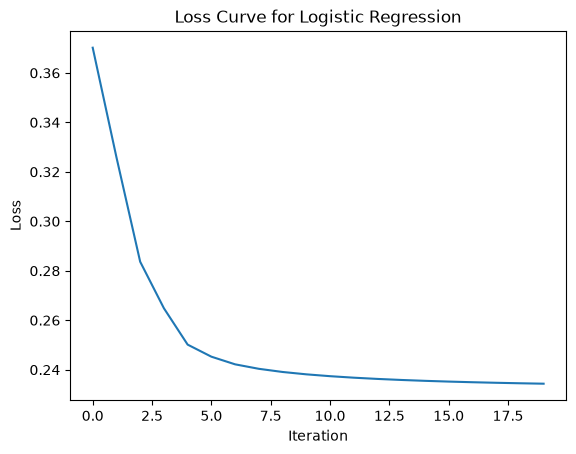

In [ ]:
# ok, first with logistic regression: we train it on the whole training set, and then we plot the loss curve. That it is!
step_size = 3
max_iters = 20

### gonna leave like that

t = LogisticRegress(max_iters=max_iters, gamma=step_size, track_history=True)
t.fit(y_train, bias_std_decorr_mean_trim_x_train)
losses = t.train_loss


plt.figure()
plt.plot(range(len(losses)), losses)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss Curve for Logistic Regression')
plt.show()





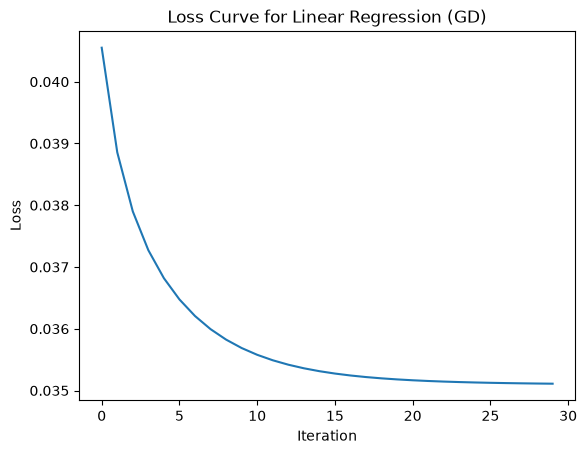

In [85]:
### now, same for linear regression with gradient descent
step_size = 0.1
max_iters = 30

t2 = LinearRegressGD(max_iters=max_iters, gamma=step_size, track_history=True)
t2.fit(y_train, bias_std_decorr_mean_trim_x_train)
losses2 = t2.train_loss

plt.figure()
plt.plot(range(len(losses2)), losses2)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss Curve for Linear Regression (GD)')
plt.show()

In [88]:
### now finally for sgd
step_size = 0.0001
max_iters = 25*1000
t3 = LinearRegressSGD(max_iters=max_iters, gamma=step_size, track_history=True)
t3.fit(y_train, bias_std_decorr_mean_trim_x_train)
losses3 = t3.train_loss

plt.figure()
plt.plot(range(len(losses3)), losses3)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss Curve for Linear Regression (SGD)')
plt.show()



KeyboardInterrupt: 